## Homework 4


In this homework, we will use the 2026 lead-scoring dataset. Download it from [here](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv).


In this dataset our desired target for classification task will be `converted` variable - has the client signed up to the platform or not. 


In [587]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import KFold
import matplotlib.pyplot as plt


### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```


In [588]:
df = pd.read_csv('../03-ML_for_Classification/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [589]:
# checking each variable's data type
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [590]:
# checking df's shape
df.shape

(5000, 9)

In [591]:
# checking missing values
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

We can see that all the categorical features have missing values; As for numerical features, only `annual_income` and `lead_score` contain missing values.

In [592]:
categoricals = [
    'lead_source',
    'industry',
    'employment_status',
    'location',
]

numericals = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score'
]

#### Missing value replacement:

In [593]:
for col in categoricals:
    df[col] = df[col].fillna('NA')
    print(f'#{col}:')
    print(df[col].unique())
    print()

#lead_source:
<StringArray>
['organic_search', 'social_media', 'referral', 'paid_ads', 'NA', 'events']
Length: 6, dtype: str

#industry:
<StringArray>
[   'technology',        'retail', 'manufacturing',     'education',
    'healthcare',            'NA',       'finance']
Length: 7, dtype: str

#employment_status:
<StringArray>
['employed', 'student', 'NA', 'unemployed', 'self_employed']
Length: 5, dtype: str

#location:
<StringArray>
['europe', 'south_america', 'NA', 'north_america', 'africa', 'asia']
Length: 6, dtype: str



In [594]:
for col in ['annual_income', 'lead_score']:
    df[col] = df[col].fillna(0.0)
    print(f'#{col}:')
    print(df[col].isnull().sum())

#annual_income:
0
#lead_score:
0


In [595]:
# split the data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train.converted
y_val = df_val.converted
y_full_train = df_full_train.converted
y_test = df_test.converted

del df_train['converted']
del df_val['converted']
# del df_full_train['converted']
del df_test['converted']

----

### Question 1:ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that
- For each numerical variable, use it as score (a.k.a. prediction) and compute the AUC with the `y` variable as ground truth.
- Use the training dataset for that

If your AUC is `< 0.5`, invert this variable by putting "-" in front
(e.g. `-df_train['balance']`)
AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?
- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [596]:
# lead_score
round(roc_auc_score(df['converted'], df['lead_score']), 3)

0.787

In [597]:
# number_of_courses_viewed
round(roc_auc_score(df['converted'], df['number_of_courses_viewed']), 3)

0.723

In [598]:
# interaction count
round(roc_auc_score(df['converted'], df['interaction_count']), 3)

0.762

In [599]:
# annual income
round(roc_auc_score(df['converted'], df['annual_income']), 3)

0.61

**Ans:** `lead_score` has the highest AUC with the value `0.787`.

----

### Question 2: Training the model
Apply one-hot-encoding use `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)
- 0.532
- 0.632
- 0.732
- 0.832

In [600]:
model = LogisticRegression(solver= 'liblinear', C = 1.0, max_iter = 1000, random_state=1)

In [601]:
# Applying One-Hot-encoding
dicts_train = df_train.to_dict(orient = 'records')

dv = DictVectorizer(sparse = False)
dv.fit(dicts_train)

dicts_val = df_val.to_dict(orient = 'records')

In [602]:
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [603]:
X_train = dv.transform(dicts_train)
X_val = dv.transform(dicts_val)

In [604]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1

In [605]:
y_pred = model.predict_proba(X_val)[:, 1]

round(roc_auc_score(y_val, y_pred), 3)

0.732

**Ans:** the AUC of `y_pred` and `y_val` is `0.732`.

----

### Question 3: Precision and Recall
Now let's compute precision and recall for our model. 
- Evaluate the model on recall for our model.
- For each threshold, compute precision and recall
- Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference betwen precision and recall. 
- 0.43
- 0.63
- 0.73
- 0.83

In [606]:
thresholds = np.linspace(0.0, 1.0, 101)
precision_set = []
recall_set = []

In [607]:
thresholds

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [608]:
for t in thresholds:
    act_positive = (y_val == 1)
    act_negative = (y_val == 0)
    pred_positive = (y_pred >= t)
    pred_negative = (y_pred < t)
    
    tp = (pred_positive & act_positive).sum()
    tn = (pred_negative & act_negative).sum()
    fp = (pred_positive & act_negative).sum()
    fn = (pred_negative & act_positive).sum()
    
    precision = (tp) / (tp + fp)
    recall = (tp) / (tp + fn)
    
    precision_set.append(precision)
    recall_set.append(recall)

/var/folders/k8/42pk1pj53f5c9rsmv597vw1h0000gn/T/ipykernel_21220/2042708571.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = (tp) / (tp + fp)


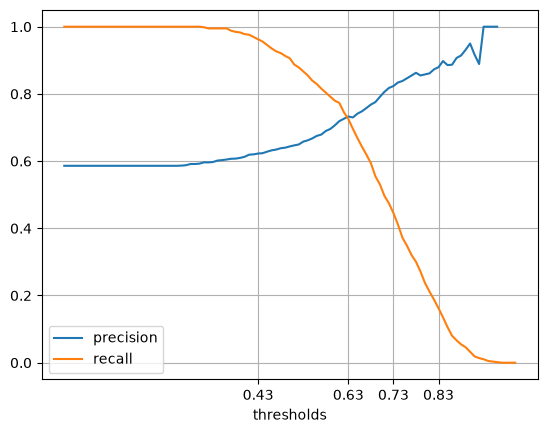

In [609]:
plt.plot(thresholds, precision_set, label = 'precision')
plt.plot(thresholds, recall_set, label = 'recall')
plt.xticks([0.43, 0.63, 0.73, 0.83]) # options from question 3
plt.xlabel('thresholds')
plt.grid()
plt.legend();

**Ans:** According to the plot above, threshold = `0.63` brings the smallest absolute difference between calculated precision and recall.

----

### Question 4: F1 score
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both.

This is the formula for computing F1:

$$F_{1} = 2 \times \frac{P \times R}{P + R}$$

where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?
- 0.21
- 0.41
- 0.61
- 0.81

In [610]:
thresholds = np.linspace(0.0, 1.0, 101)
F1_set = []
ans = (float('-inf'), -1)

In [611]:
for t in thresholds:
    act_positive = (y_val == 1)
    act_negative = (y_val == 0)
    pred_positive = (y_pred >= t)
    pred_negative = (y_pred < t)
    
    tp = (pred_positive & act_positive).sum()
    tn = (pred_negative & act_negative).sum()
    fp = (pred_positive & act_negative).sum()
    fn = (pred_negative & act_positive).sum()
    
    precision = (tp) / (tp + fp)
    recall = (tp) / (tp + fn)
    
    F1 = 2 * (precision * recall) / (precision + recall)
    F1_set.append(F1)
    ans = max(ans, (F1, t))

/var/folders/k8/42pk1pj53f5c9rsmv597vw1h0000gn/T/ipykernel_21220/957220384.py:12: RuntimeWarning: invalid value encountered in scalar divide
  precision = (tp) / (tp + fp)


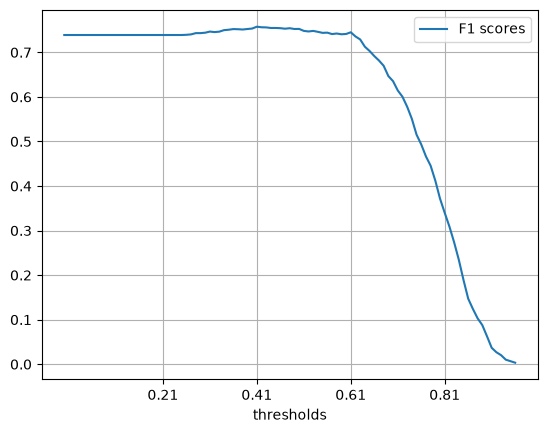

In [612]:
plt.plot(thresholds, F1_set, label = 'F1 scores')
plt.xticks([0.21, 0.41, 0.61, 0.81])
plt.xlabel('thresholds')
plt.grid()
plt.legend();

In [613]:
round(ans[0], 3), round(ans[1], 3)

(np.float64(0.758), np.float64(0.41))

**Ans:** When threshold = `0.41`, we can obtain the largest F1 score = `0.758`.

----

### Question 5: 5-Fold CV
Use the `KFold` class from Scikit-Learn to evaluate our model on  different folds:

```python
KFold(n_splits=5, shuffle=True, random_state=1)
```

- iterate over different folds of `df_full_train`
- Split the data into train and validation
- Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?
- 0.001
- 0.007
- 0.013
- 0.060

In [614]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [615]:
def train(df_train, y_train, C = 1.0):
    dicts = df_train[categoricals + numericals].to_dict(orient = 'records')
    dv = DictVectorizer(sparse = False)
    X_train = dv.fit_transform(dicts)
    
    model = LogisticRegression(solver='liblinear', C = C, max_iter = 1000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categoricals + numericals].to_dict(orient = 'records')
    
    X = dv.transform(dicts)
    
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

In [616]:
scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    
    y_train = df_train.converted.values
    y_val = df_val.converted.values
    
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)
    
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)
np.std(scores).round(3)

np.float64(0.007)

**Ans:** The standard deviation of AUC scores (across 5 different folds) is `0.007`.

----

### Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter `C`

- Iterate over the following `C` values: `[0.000001, 0.001, 1]`
- Initialize KFold with the same parameters as previously
- Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.


In [617]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
        
        y_train = df_train.converted.values
        y_val = df_val.converted.values
        
        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
        
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    print(f'C = {C} | mean: {np.mean(scores).round(3)} | std: {np.std(scores).round(3)}')

C = 1e-06 | mean: 0.617 | std: 0.019
C = 0.001 | mean: 0.749 | std: 0.01
C = 1 | mean: 0.732 | std: 0.007


**Ans:** `C = 0.001` offers the largest average of ROC AUC scores: `mean = 0.749` with the standard deviation: `0.01`.

----

End of this page